In [104]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

conn = sqlite3.connect(':memory:')

df = pd.read_csv('ai-career-threat-index.csv')

df.to_sql('jobs',conn,index=False)

higher_risk_qry = """
    SELECT title,score
    FROM jobs
    ORDER BY score DESC
    LIMIT 10;
"""

higher_risk = pd.read_sql_query(higher_risk_qry,conn)
higher_risk
pd.set_option('display.max_columns', None)

higher_risk.to_csv('higher_risk_areas.csv')




In [106]:
lower_risk_qry = """
    SELECT title,score
    FROM jobs
    ORDER BY score ASC
    LIMIT 10
"""

lower_risk = pd.read_sql_query(lower_risk_qry,conn)
lower_risk
lower_risk.to_csv('lower_risk_areas.csv')

In [107]:
higher_risk_categories_query = """
    SELECT category,COUNT(*) as very_high_level_count
    FROM jobs
    WHERE risk_level IN ('Very High','High')
    GROUP BY category
    ORDER BY very_high_level_count DESC
    LIMIT 5;
"""

higher_risk_categories = pd.read_sql_query(higher_risk_categories_query,conn)
higher_risk_categories
higher_risk_categories.to_csv('higher_risk_categories.csv')

In [44]:
avg_salary = (df['salary_low_usd'] + df['salary_high_usd']) / 2
df_cor = df.copy()
df_cor['avg_salary'] = avg_salary

df_correlation = df_cor['avg_salary'].corr(df['score'])
df_correlation

np.float64(-0.14129299421929487)

In [108]:
declining_roles_qry = """
    SELECT title,salary_trend,sub_task_automation,
    CASE
        WHEN sub_task_automation BETWEEN 66 AND 100 THEN "automatizavel"
        ELSE "não automatizavel" END AS automatização
    FROM jobs
    WHERE salary_trend = 'declining'
    ORDER BY sub_task_automation DESC;
        
"""

declining_roles = pd.read_sql_query(declining_roles_qry,conn)
declining_roles
declining_roles.to_csv('declining_roles.csv')

In [117]:
percentage_grow_qry = """
    SELECT title,((score_q3_2026/score_q1_2025) - 1) * 100 as scoring_grow_rate
    FROM jobs
    ORDER BY scoring_grow_rate DESC
    LIMIT 10;
"""

percentage_grow = pd.read_sql_query(percentage_grow_qry,conn)
percentage_grow.to_csv('percentage_grow.csv')

In [56]:
    correlation = df.sub_tool_maturity.corr(df.sub_adoption)
    correlation

np.float64(0.9376654066468646)

,slug,title,category,score,risk_level,salary_low_usd,salary_high_usd,salary_trend,tasks_at_risk_count,tasks_growing_count,defense_skill_1,defense_skill_2,defense_skill_3,insight,score_q1_2025,score_q3_2025,score_q1_2026,score_q2_2026,score_q3_2026,soc_code,tier,sub_task_automation,sub_tool_maturity,sub_adoption,sub_agentic_exposure,agentic_risk
15,data-scientist,Data Scientist,Technology,28,Low,120000,190000,rising,4,3,Directing Agentic Data Pipelines & AutoML,LLM Fine-Tuning & Evaluation,AI Strategy & Business Translation,Agentic notebooks can now run an entire clean-...,14.0,16.0,18.0,20.0,28,15-2051,1,32,58,48,40,Moderate


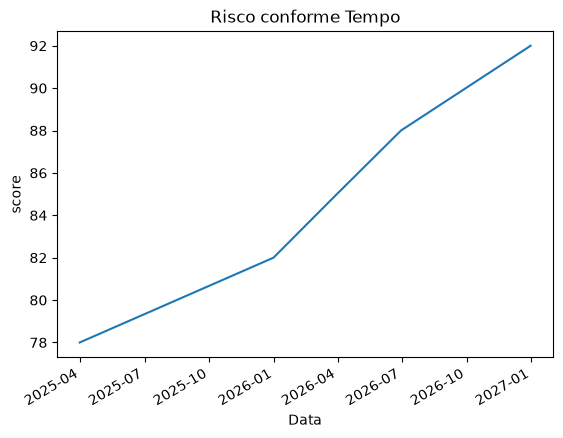

In [118]:
evo = df[df['score'] == df['score'].max()][['score_q1_2025','score_q3_2025','score_q1_2026','score_q2_2026','score_q3_2026']]
evo = evo.melt()['value']
datas = pd.to_datetime(['2025-03-31', '2025-12-31', '2026-03-31', '2026-06-30', '2026-12-31'])
evo.index = datas


evo.plot(kind='line',xlabel='Data',ylabel='score',title='Risco conforme Tempo')
plt.savefig('riscoXtempo',dpi=300)

